# E1 — Soft hunt-phase centre-bias calibration

Frozen-weight post-selection analysis of $\lambda\in\{0,.04,.08,.12\}$ under rule-based and external-mixed opponent pools. The unique primary metric is mean score. Hunt-phase distance, centre-progress rate, and centre occupancy explain the behavioural mechanism.

## Locked protocol

The base experiment uses 20 seed clusters (65001–65020), five rounds per cluster, four inference-only variants, and four lineups. A targeted direct-comparison extension adds seeds 65021–65040 only for $\lambda=.04/.12$ in external mixed and frozen DDDQN. The complete E1 record therefore contains 2,000 rounds; the targeted contrasts use 40 paired seed clusters while all other contrasts retain 20. Every addition is append-only and all earlier rounds remain unchanged. Inference uses zero exploration and unchanged checkpoints. Statistical resampling uses paired seed clusters, never individual rounds or decision states.

In [1]:
from __future__ import annotations
import json, subprocess, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
RESULT_ROOT = ROOT / 'results' / 'e1_soft_center_bias'
VARIANTS = ['center_00', 'center_04', 'center_08', 'center_12']
LINEUPS = ['rule3', 'external_mixed', 'internal_mixed', 'frozen_dddqn']
SEEDS = list(range(65001, 65021))
DIRECT_SEEDS = list(range(65021, 65041))
ROUNDS = 5
RUN_SUITE = True
subprocess.run([sys.executable, 'evaluation/e1_soft_center_bias.py', 'prepare'], cwd=ROOT, check=True)
protocol = json.loads((RESULT_ROOT / 'protocol.json').read_text())
protocol

{'experiment': 'E1 soft hunt-phase centre-bias calibration',
 'scenario': 'classic',
 'variants': {'center_00': {'agent': 'dueling_hunt_center_0', 'lambda': 0.0},
  'center_04': {'agent': 'dueling_hunt_center_04', 'lambda': 0.04},
  'center_08': {'agent': 'dueling_hunt_center_04', 'lambda': 0.08},
  'center_12': {'agent': 'dueling_hunt_center_12', 'lambda': 0.12}},
 'lineups': {'rule3': ['rule_based_agent',
   'rule_based_agent',
   'rule_based_agent'],
  'external_mixed': ['external_feature_is_everything',
   'external_deep_learning_killer',
   'rule_based_agent'],
  'internal_mixed': ['frozen_ddqn_day7',
   'frozen_sarsa_best',
   'frozen_linear_q_final'],
  'frozen_dddqn': ['dueling_ddqn_agent',
   'frozen_ddqn_day7',
   'frozen_ddqn_day11']},
 'seeds': [65001,
  65002,
  65003,
  65004,
  65005,
  65006,
  65007,
  65008,
  65009,
  65010,
  65011,
  65012,
  65013,
  65014,
  65015,
  65016,
  65017,
  65018,
  65019,
  65020],
 'direct_extension': {'seeds': [65021,
   65022,
   6

## Run ledger

Completed runs with matching provenance hashes are reused. Missing runs are executed one seed cluster at a time, so interruption does not invalidate completed work.

In [2]:
if RUN_SUITE:
    for lineup in LINEUPS:
        for variant in VARIANTS:
            run_seeds = SEEDS + (DIRECT_SEEDS if lineup in {'external_mixed','frozen_dddqn'} and variant in {'center_04','center_12'} else [])
            for seed in run_seeds:
                manifest = RESULT_ROOT / 'manifests' / lineup / variant / f'seed_{seed}.run.json'
                if manifest.exists():
                    continue
                print('RUN', lineup, variant, seed, flush=True)
                subprocess.run([sys.executable, 'evaluation/e1_soft_center_bias.py', 'run',
                                '--variant', variant, '--lineup', lineup,
                                '--seed', str(seed), '--rounds', str(ROUNDS)],
                               cwd=ROOT, check=True)
subprocess.run([sys.executable, 'evaluation/e1_soft_center_bias.py', 'summarize'], cwd=ROOT, check=True)
payload = json.loads((RESULT_ROOT / 'summary.json').read_text())
len(payload['round_rows']), len(payload['seed_rows'])

(2000, 400)

## Aggregate outcomes

In [3]:
aggregate = pd.DataFrame(payload['aggregate'])
display(aggregate[['lineup','variant','lambda','seed_clusters','rounds','score','coins','crates','kills','suicides','invalid','survived','action_ms']].round(4))

,lineup,variant,lambda,seed_clusters,rounds,score,coins,crates,kills,suicides,invalid,survived,action_ms
0,rule3,center_00,0.00,20,100,4.330,3.28,30.660,0.210,0.23,1.550,0.700,2.7058
1,rule3,center_04,0.04,20,100,4.330,3.28,30.660,0.210,0.23,1.520,0.700,2.8576
2,rule3,center_08,0.08,20,100,4.330,3.28,30.660,0.210,0.21,1.500,0.720,2.9785
3,rule3,center_12,0.12,20,100,4.380,3.28,30.660,0.220,0.21,1.520,0.720,2.9643
4,external_mixed,center_00,0.00,20,100,2.990,1.64,23.080,0.270,0.11,3.280,0.760,3.3857
5,external_mixed,center_04,0.04,40,200,2.820,1.62,22.820,0.240,0.14,3.380,0.715,4.0451
6,external_mixed,center_08,0.08,20,100,2.990,1.64,23.080,0.270,0.12,3.140,0.750,4.5963
7,external_mixed,center_12,0.12,40,200,2.920,1.62,22.820,0.260,0.12,3.385,0.735,3.9039
8,internal_mixed,center_00,0.00,20,100,2.840,2.29,30.920,0.110,0.08,2.440,0.910,2.7948
9,internal_mixed,center_04,0.04,20,100,2.890,2.29,30.920,0.120,0.08,2.380,0.910,3.0486


## Hunt-phase mechanism

In [4]:
mechanism = ['hunt_prevalence','hunt_mean_center_distance','hunt_center_progress_rate',
             'hunt_center_occupancy','hunt_wait_rate','hunt_revisit_rate',
             'hunt_two_cycle_rate','hunt_duration','timeout']
display(aggregate[['lineup','variant','lambda',*mechanism]].round(4))

,lineup,variant,lambda,hunt_prevalence,hunt_mean_center_distance,hunt_center_progress_rate,hunt_center_occupancy,hunt_wait_rate,hunt_revisit_rate,hunt_two_cycle_rate,hunt_duration,timeout
0,rule3,center_00,0.00,0.2085,0.2058,0.0442,0.8716,0.0290,0.4245,0.0839,83.20,0.840
1,rule3,center_04,0.04,0.2064,0.1976,0.0421,0.8772,0.0284,0.4282,0.0834,82.36,0.840
2,rule3,center_08,0.08,0.2093,0.2249,0.0458,0.8619,0.0282,0.4297,0.0824,83.66,0.860
3,rule3,center_12,0.12,0.2093,0.2177,0.0449,0.8645,0.0299,0.4355,0.0831,83.66,0.860
4,external_mixed,center_00,0.00,0.3650,0.2341,0.0475,0.8628,0.0284,0.4105,0.0771,145.48,0.940
5,external_mixed,center_04,0.04,0.3422,0.2314,0.0476,0.8642,0.0324,0.4210,0.0768,135.18,0.920
6,external_mixed,center_08,0.08,0.3622,0.2200,0.0444,0.8718,0.0292,0.4158,0.0784,143.53,0.940
7,external_mixed,center_12,0.12,0.3443,0.1923,0.0443,0.8831,0.0336,0.4314,0.0782,136.62,0.945
8,internal_mixed,center_00,0.00,0.4446,0.2965,0.0645,0.8205,0.0338,0.4284,0.0829,175.67,1.000
9,internal_mixed,center_04,0.04,0.4473,0.2755,0.0616,0.8311,0.0339,0.4279,0.0830,176.29,1.000


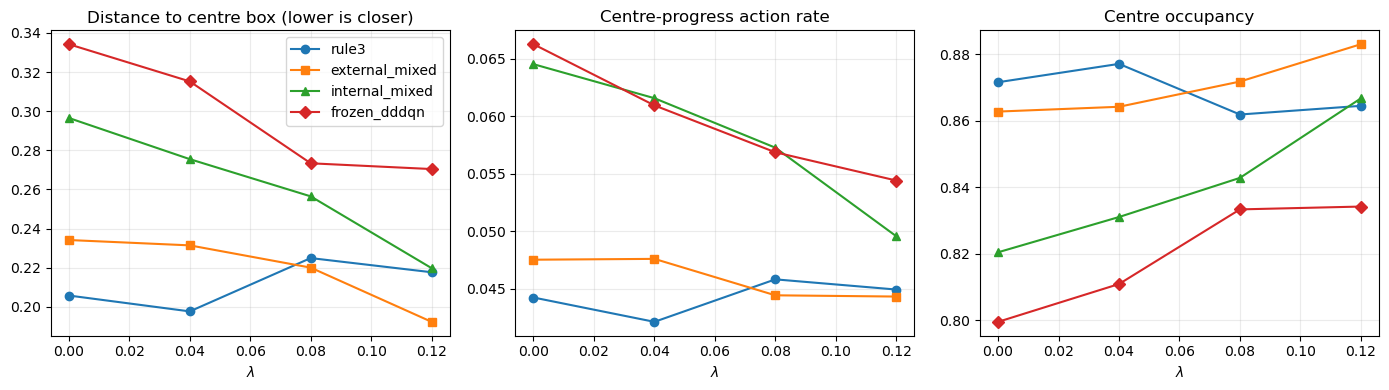

In [5]:
seed_df = pd.DataFrame(payload['seed_rows'])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric, title in zip(axes,
    ['hunt_mean_center_distance','hunt_center_progress_rate','hunt_center_occupancy'],
    ['Distance to centre box (lower is closer)','Centre-progress action rate','Centre occupancy']):
    for lineup, marker in [('rule3','o'),('external_mixed','s'),('internal_mixed','^'),('frozen_dddqn','D')]:
        part = seed_df[seed_df.lineup == lineup].groupby('lambda')[metric]
        x = np.array(sorted(part.groups))
        y = np.array([part.get_group(v).mean() for v in x])
        ax.plot(x, y, marker=marker, label=lineup)
    ax.set(title=title, xlabel='$\lambda$'); ax.grid(alpha=.25)
axes[0].legend(); fig.tight_layout()
figure_dir = RESULT_ROOT / 'figures'; figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / 'hunt_mechanism_dose_response.png', dpi=180, bbox_inches='tight'); plt.show()

## Paired seed-cluster inference

In [6]:
bootstrap = pd.DataFrame(payload['paired_bootstrap'])
display(bootstrap.round(4))
score_bootstrap = bootstrap[bootstrap.metric == 'score'].copy()
score_bootstrap[['ci_low','ci_high']] = pd.DataFrame(score_bootstrap.ci95.tolist(), index=score_bootstrap.index)
display(score_bootstrap[['lineup','contrast','mean_difference','ci_low','ci_high','positive_seeds','nonmissing_seeds']].round(4))

,lineup,contrast,metric,mean_difference,ci95,positive_seeds,nonmissing_seeds
0,rule3,center_04-center_00,score,0.0000,"[0.0, 0.0]",0,20
1,rule3,center_04-center_00,invalid,-0.0300,"[-0.12999999999999998, 0.07000000000000002]",2,20
2,rule3,center_04-center_00,suicides,0.0000,"[0.0, 0.0]",0,20
3,rule3,center_04-center_00,hunt_mean_center_distance,-0.0081,"[-0.027036648732599363, 0.0070517736407362894]",4,20
4,rule3,center_04-center_00,hunt_center_progress_rate,-0.0021,"[-0.005502907002746985, 0.0005317136360619218]",2,20
...,...,...,...,...,...,...,...
67,frozen_dddqn,center_04-center_12,invalid,-0.0600,"[-0.22499999999999992, 0.09000000000000002]",16,40
68,frozen_dddqn,center_04-center_12,suicides,0.0400,"[0.0, 0.08499999999999999]",8,40
69,frozen_dddqn,center_04-center_12,hunt_mean_center_distance,0.0448,"[0.02397422282411408, 0.06441232073229078]",32,40
70,frozen_dddqn,center_04-center_12,hunt_center_progress_rate,0.0065,"[0.0029380218005579605, 0.01028661013011387]",29,40


,lineup,contrast,mean_difference,ci_low,ci_high,positive_seeds,nonmissing_seeds
0,rule3,center_04-center_00,0.00,0.000,0.000,0,20
6,rule3,center_04-center_08,0.00,0.000,0.000,0,20
12,rule3,center_04-center_12,-0.05,-0.150,0.000,0,20
18,external_mixed,center_04-center_00,0.05,0.000,0.150,1,20
24,external_mixed,center_04-center_08,0.05,-0.100,0.200,2,20
30,external_mixed,center_04-center_12,-0.10,-0.300,0.100,5,40
36,internal_mixed,center_04-center_00,0.05,-0.100,0.200,2,20
42,internal_mixed,center_04-center_08,0.05,-0.100,0.250,2,20
48,internal_mixed,center_04-center_12,0.05,-0.200,0.350,2,20
54,frozen_dddqn,center_04-center_00,0.10,-0.100,0.350,2,20


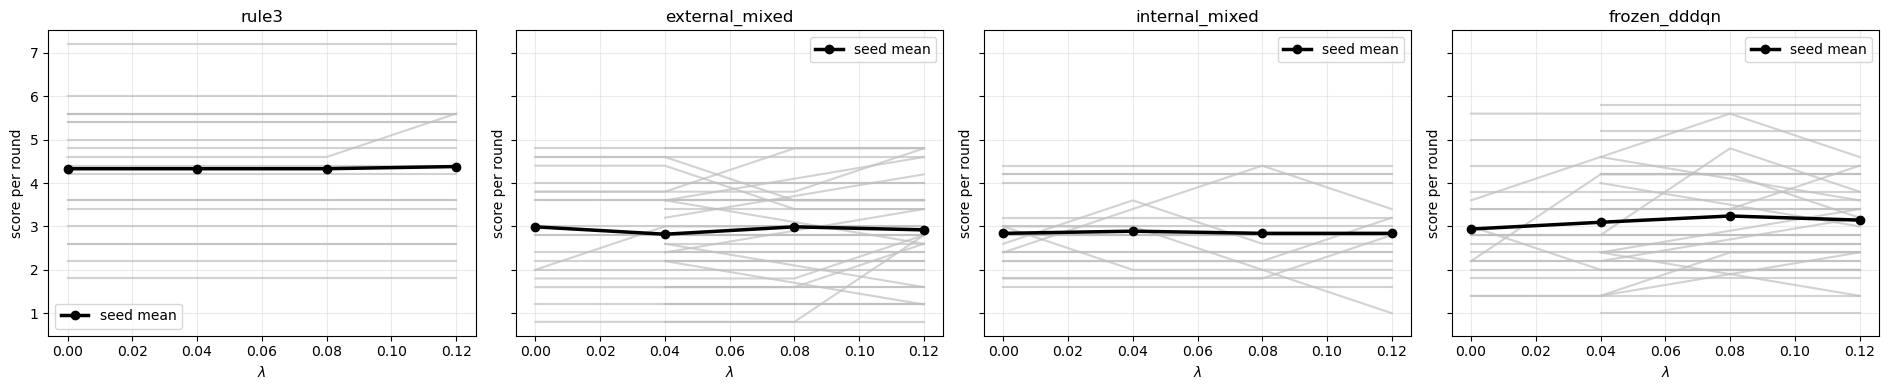

In [7]:
fig, axes = plt.subplots(1, len(LINEUPS), figsize=(19, 4), sharey=True)
for ax, lineup in zip(axes, LINEUPS):
    part = seed_df[seed_df.lineup == lineup]
    for seed, group in part.groupby('seed'):
        group = group.sort_values('lambda'); ax.plot(group['lambda'], group['score'], color='0.75', alpha=.7)
    means = part.groupby('lambda')['score'].mean()
    ax.plot(means.index, means.values, color='black', marker='o', linewidth=2.5, label='seed mean')
    ax.set(title=lineup, xlabel='$\lambda$', ylabel='score per round'); ax.grid(alpha=.25); ax.legend()
fig.tight_layout(); fig.savefig(figure_dir / 'paired_seed_score_profiles.png', dpi=180, bbox_inches='tight'); plt.show()

## Result interpretation

Across the 100 rule-based rounds per variant, $\lambda=0$, $.04$, and $.08$ all obtained mean score 4.33; $\lambda=.12$ obtained 4.38, with paired $.04-.12$ interval $[-0.15,0.00]$. External mixed and frozen DDDQN received a targeted extension, so their $.04/.12$ estimates below use 40 seeds and 200 rounds per condition; their $.00/.08$ estimates remain based on the original 20 seeds and must not be treated as equal-sample direct comparisons.

In the 40-seed external-mixed direct comparison, $.04$ versus $.12$ mean scores were 2.82 and 2.92, giving $.04-.12=-0.10$ with 95% paired bootstrap interval $[-0.30,0.10]$. Invalid actions were 3.380 versus 3.385 ($\Delta=-0.005$, interval $[-0.255,0.245]$). Suicides were 0.14 versus 0.12 ($\Delta=0.02$, interval $[0.00,0.045]$). The centre mechanism remained visible: $.12$ had smaller mean centre-box distance (0.192 vs. 0.231) and greater occupancy (0.883 vs. 0.864). The expanded evidence therefore favors $.12$ descriptively on score and safety, while the score interval still includes zero.

In the added internal-mixed lineup, mean scores for $\lambda=0$, $.04$, $.08$, and $.12$ were 2.84, 2.89, 2.84, and 2.84. The paired $.04-.12$ difference was 0.05 with a 95% seed-cluster bootstrap interval of $[-0.20,0.35]$. Economic metrics again remained identical. Increasing $\lambda$ produced a clear positional gradient: mean centre-box distance fell from 0.297 to 0.220 and occupancy rose from 0.820 to 0.867, while $.12$ had fewer suicides (0.06) and higher survival (0.93). Thus internal mixed provides weak descriptive support for $.04$ on score, but no interval-level evidence that it outperforms the other settings.

In the 40-seed frozen-DDDQN direct comparison, $.04$ versus $.12$ mean scores were 3.095 and 3.145, giving $.04-.12=-0.05$ with interval $[-0.225,0.125]$. Invalid actions were 3.22 versus 3.28 ($\Delta=-0.06$, interval $[-0.225,0.09]$). Suicides were 0.30 versus 0.26 ($\Delta=0.04$, interval $[0.00,0.085]$). Again $.12$ moved the policy closer to the centre (distance 0.270 vs. 0.315; occupancy 0.834 vs. 0.811). The added seeds attenuate the original score gap but preserve the same direction: $.12$ is descriptively better on score and suicide rate, with no clear invalid-action difference.

## Interpretation guardrail

This is a post-selection calibration analysis. Results may support the selected weak prior under the evaluated pools, but do not establish that $\lambda=.04$ is universally optimal. Mixed or adverse results must be reported without changing the submitted policy.